# POGOS: SOSSSISSE step-by-step

This is the basic steps to run just the SOSSISSE steps using a POGOS yaml 
file.

This assumes you have run `pogos_setup.py` first to generate the file structure and the yaml file mentioned below.

## Imports and notebook setup

In [1]:
import numpy as np

from sossisse.core import io
from sossisse.core import misc
from sossisse.general import general
from sossisse.general import plots

from pogos.resources import nb_funcs

## Yaml file definition

Set the path to the POGOS yaml file here

In [2]:
yaml_file = '/scratch3/jwst/pogos-data/soss_test.yaml'

## Initialization

POGOS and SOSSISSE initialization, don't change this section

In [3]:
# pogos sossisse init
inst = nb_funcs.sossisse_init(yaml_file)
# linear recon initialization
general.linear_recon_init(inst)


                       ╔════════════════════════╗
                       ║ ╔═╗╔═╗╔═╗╔═╗╦╔═╗╔═╗╔═╗ ║
                       ║ ╚═╗║ ║╚═╗╚═╗║╚═╗╚═╗║╣  ║
                       ║ ╚═╝╚═╝╚═╝╚═╝╩╚═╝╚═╝╚═╝ ║
                       ╚════════════════════════╝

************************************************************************************************************************
SOSSISSE: v0.1.057 - 2025-04-07
************************************************************************************************************************
13:57:05.44│         Using parameter file: /scratch3/jwst/pogos-data/soss_test.yaml

            ╔═══════════════════════════════════════════════════════════════════╗
            ║ ╦  ┬┌┐┌┌─┐┌─┐┬─┐   ╦═╗┌─┐┌─┐┌─┐┌┐┌   ╔╦╗┬─┐┌─┐┌─┐┌─┐┬┌─┐┌┬┐ ┐ ┌┐  ║
            ║ ║  ││││├┤ ├─┤├┬┘   ╠╦╝├┤ │  │ ││││    ║ ├┬┘├─┤├─┘├─┘│└─┐ │  │ ├┴┐ ║
            ║ ╩═╝┴┘└┘└─┘┴ ┴┴└─   ╩╚═└─┘└─┘└─┘┘└┘    ╩ ┴└─┴ ┴┴  ┴  ┴└─┘ ┴ ─┴─└─┘ ║
            ╚════════════════════════════════════════════════

True

## Update constants

Here you can update constants


In [4]:
# inst.params[PARAM_NAME] = VALUE

## Load the data and apply DQ


In [5]:
# load the image, error and data quality
cube, err, dq = inst.load_data_with_dq()

13:57:38.20│ Reading temporary file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_initial_cube.fits
13:57:38.42│ Reading temporary file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_initial_err.fits
13:57:38.62│ Reading temporary file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_initial_dq.fits


# Apply the flat field

In [6]:
# Apply the flat field
cube, err, dq = inst.apply_flat_field(cube, err, dq)

13:57:47.98│ Reading ff file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_ff_cube.fits
13:57:48.17│ Reading ff file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_ff_err.fits
13:57:48.35│ Reading ff file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_ff_dq.fits


# Keep only certain Data Quality flags

In [7]:
# apply the dq to the cube
cube, err = inst.apply_dq(cube, err, dq)

13:57:52.87│ Accepting DQ = 0
13:57:53.03│ Accepting DQ = 2


## Remove background

14:03:21.63│ Apply the background model correction
14:03:22.03│         Tweaking the position of the background


100%|██████████| 51/51 [00:02<00:00, 21.02it/s]

14:03:24.47│         Here we just take the offset to be 0 (Optimal obackgroun offset not found)



100%|██████████| 153/153 [00:00<00:00, 1785.85it/s]


14:03:24.68│ Plotting graph: background1.png
14:03:25.02│ Plotting graph: background1.pdf


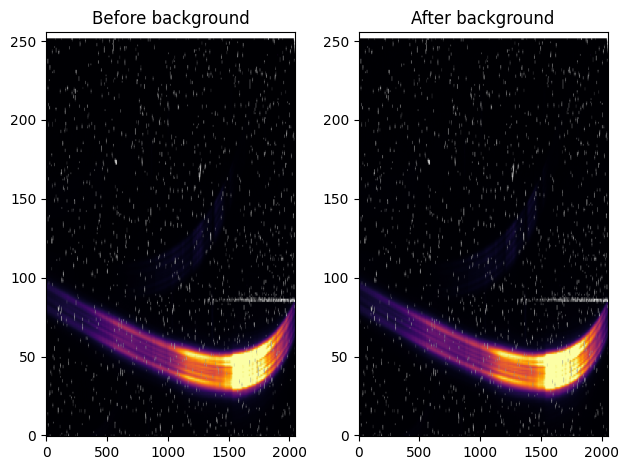

In [14]:
# remove the background
cube, err = inst.remove_background(cube, err)

# Low pass the data

In [9]:
# low pass the data
cube, err = inst.low_pass_filter(cube, err)

13:58:53.53│ Reading temporary file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_initial_cube_bkgrnd2.fits
13:58:53.54│ Reading temporary file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_initial_err_bkgrnd2.fits


## Patch isolated bad pixels

In [11]:
# for each slice of the cube, isolated bad pixels are interpolated with the
# value of their 4 neighbours.
cube, err = inst.patch_isolated_bads(cube, err)

14:00:02.34│ patch_isolated_bads:     we read temporary files to speed things up.  Reading:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_cleaned_isolated.fits


## Remove cosmic rays

In [12]:
# remove cosmic rays with a sigma cut
cube = inst.remove_cosmic_rays(cube)

14:00:44.34│ We remove cosmisc rays
14:00:44.35│         Calculating median of 1-sigma cube


100%|██████████| 153/153 [00:00<00:00, 325.70it/s]


# Use PASTASOSS (if required)

In [15]:
# code here

## Get the trace map

In [16]:
# get the trace map
tracemap = inst.get_trace_mask()

14:03:46.75│ Getting the trace mask


## Differential 1/f correction

In [17]:
cube, med, transit_invsout = inst.clean_1f(cube, err, tracemap)

14:03:55.10│ We read temporary files to speed things up.
14:03:55.11│         Reading:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/median.fits
14:03:55.12│         Reading:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/cleaned_cube.fits
14:03:55.31│         Reading:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_transit_in_vs_out.fits


## PCA Analysis

Note turn this off with 

```
SOSSISSE.WLC.LMODEL.FIT_PCA = False
```

In [18]:
# construct the principal component model from the out of transit domain
# using pca (we deal with not fitting the PCA inside)
pcas = inst.fit_pca(cube, err, med, tracemap)

14:04:06.98│ WLC.LMODEL.FIT_PCA=False  WLC.LMODEL.FIT_N_PCA=0Not fitting with PCA


## Recenter the trace position

14:04:09.63│ Recentering trace position
14:04:09.64│         Scan to optimize position of trace


100%|██████████| 52/52 [00:00<00:00, 142272.54it/s]

14:04:09.67│ Best dx : 0 pix
14:04:09.68│ Best dy : 0 pix
14:04:09.69│         offset dy = -26.000000, err = nan ppt
14:04:09.70│         offset dy = -25.000000, err = nan ppt
14:04:09.71│         offset dy = -24.000000, err = nan ppt
14:04:09.72│         offset dy = -23.000000, err = nan ppt
14:04:09.73│         offset dy = -22.000000, err = nan ppt
14:04:09.74│         offset dy = -21.000000, err = nan ppt
14:04:09.75│         offset dy = -20.000000, err = nan ppt
14:04:09.77│         offset dy = -19.000000, err = nan ppt
14:04:09.78│         offset dy = -18.000000, err = nan ppt
14:04:09.79│         offset dy = -17.000000, err = nan ppt
14:04:09.80│         offset dy = -16.000000, err = nan ppt
14:04:09.81│         offset dy = -15.000000, err = nan ppt
14:04:09.82│         offset dy = -14.000000, err = nan ppt
14:04:09.83│         offset dy = -13.000000, err = nan ppt
14:04:09.84│         offset dy = -12.000000, err = nan ppt
14:04:09.85│         offset dy = -11.000000, err = nan pp


/scratch3/jwst/sossisse/sossisse/instruments/default.py:2351: RuntimeWarning: invalid value encountered in divide
  loss_ppt = (1 - (sums / np.nansum(sums))) * 1e3


14:04:09.87│         offset dy = -9.000000, err = nan ppt
14:04:09.88│         offset dy = -8.000000, err = nan ppt
14:04:09.89│         offset dy = -7.000000, err = nan ppt
14:04:09.90│         offset dy = -6.000000, err = nan ppt
14:04:09.91│         offset dy = -5.000000, err = nan ppt
14:04:09.92│         offset dy = -4.000000, err = nan ppt
14:04:09.94│         offset dy = -3.000000, err = nan ppt
14:04:09.95│         offset dy = -2.000000, err = nan ppt
14:04:09.96│         offset dy = -1.000000, err = nan ppt
14:04:09.97│         offset dy = 0.000000, err = nan ppt
14:04:09.98│         offset dy = 1.000000, err = nan ppt
14:04:09.99│         offset dy = 2.000000, err = nan ppt
14:04:10.00│         offset dy = 3.000000, err = nan ppt
14:04:10.01│         offset dy = 4.000000, err = nan ppt
14:04:10.02│         offset dy = 5.000000, err = nan ppt
14:04:10.03│         offset dy = 6.000000, err = nan ppt
14:04:10.04│         offset dy = 7.000000, err = nan ppt
14:04:10.05│         o

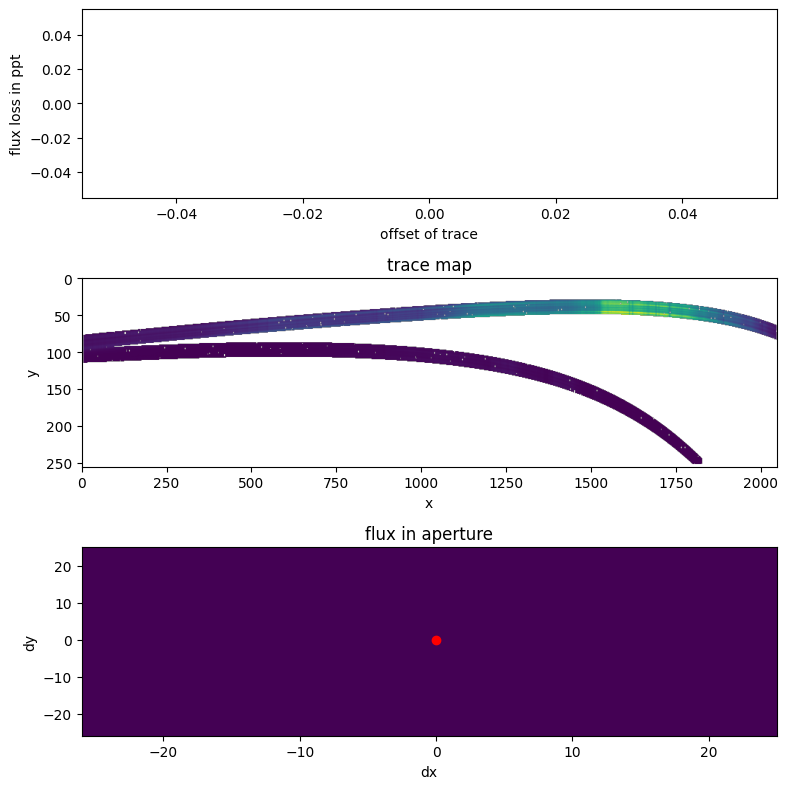

14:04:11.10│ Getting the trace mask


In [19]:
tracemap = inst.recenter_trace_position(tracemap, med)

## Linear reconstruction

In [ ]:
# get the gradients
dx, dy, rotxy, ddy, med_clean = inst.get_gradients(med)
# set up the mask for trace position
mask_out = inst.get_mask_trace_pos(med, tracemap)
mask_trace_pos, x_order0, y_order0, x_trace_pos, y_trace_pos = mask_out

# setup the linear reconstruction vector based on the input parameters
lvector = inst.setup_linear_reconstruction(med, dx, dy, rotxy, ddy,
                                           pcas)
# -----------------------------------------------------inst--------------------
# find the best linear combination of scale/dx/dy/rotation from lvector
# amps is a vector with the amplitude of all 4 fitted terms
# amps[0] -> amplitude of trace
# amps[1] -> dx normalized on reference trace
# amps[2] -> dy normalized on reference trace
# amps[3] -> rotation (in radians) normalized on reference trace
# amps[4] -> 2nd derivative in y [if option activated]
# -------------------------------------------------------------------------
amp_out = inst.apply_amp_recon(cube, err, med, mask_trace_pos,
                               lvector, x_trace_pos, y_trace_pos,
                               x_order0, y_order0)
# get outputs of apply_amp_recon
ltable, lrecon, valid_cube = amp_out

## Transit part

Section needs better name

In [ ]:
# -------------------------------------------------------------------------
# At this point we can look at the transit
inst.define_transit_ints(ltable)
# -------------------------------------------------------------------------
# normalize the trace but a normalization factor
ltable = inst.normalize_sum_trace(ltable)
# -------------------------------------------------------------------------
# per pixel baseline
if inst.params['WLC.GENERAL.PER_PIXEL_BASELINE_CORRECTION']:
    misc.printc('Performing per-pixel baseline subtraction', 'info')
    cube = inst.per_pixel_baseline(cube, valid_cube)
# -------------------------------------------------------------------------
# print the rms baseline for all methods
for method in inst.get_rms_baseline():
    # calculate the rms for this method
    rms_method = inst.get_rms_baseline(ltable['amplitude'], method=method)
    # print this
    msg = '{0}, rms = {1:.1f}ppm'.format(method, rms_method * 1e6)
    misc.printc(msg, 'number')
# -------------------------------------------------------------------------
# get the effective wavelength
photo_weighted_mean, energy_weighted_mean = inst.get_effective_wavelength()

## Save and plot the linear recon results

In [ ]:
# =========================================================================
# write files
# =========================================================================
inst.save_wlc_results(cube, err, lrecon, ltable)
# =========================================================================
# Plots and Summary HTML
# =========================================================================
# plot the stability plot
plots.plot_stability(inst, ltable)
# -------------------------------------------------------------------------
# plot the transit plot
plots.plot_transit(inst, ltable)
# -------------------------------------------------------------------------
# write the yaml file to html
io.summary_html(inst.params)

## Spectral extraction setup

In [ ]:
# get parameters from instrumental parameters
objname = inst.params['INPUTS.OBJECTNAME']
# print the white light curve splash
print(misc.art('Spectral timeseries ' + objname, 'blue', 'CYAN'))
# -------------------------------------------------------------------------
# load temporary filenames (should be run before science starts)
inst.define_filenames()
# -------------------------------------------------------------------------
# plot / save storage
storage = dict()
# get the trace orders
trace_orders = inst.get_trace_orders()

## Processing trace order loop

This is done for each order, you could remove the for loop and just set the
trace order individually
```
trace_order = 1
```

In [ ]:
# loop around trace orders
for trace_order in trace_orders:
    # print progress
    misc.printc('Processing trace order {0}'.format(trace_order), 'alert')
    # ---------------------------------------------------------------------
    # load data for this trace order
    indata = inst.load_input_spec_data(trace_order)
    med, dx, dy, rotxy, ddy, med_clean, residual, err = indata[:8]
    recon, ltable, posmax, throughput, wavegrid = indata[8:]
    # ---------------------------------------------------------------------
    # create the SED
    sp_sed = inst.create_sed(med, residual, wavegrid, posmax, throughput,
                             med_clean, trace_order)
    # ---------------------------------------------------------------------
    # load the model (and deal with masking order zero if required)
    model = inst.load_model(recon, med)
    # ---------------------------------------------------------------------
    # spectrum is the ratio of the residual to the trace model
    spec, spec_err = inst.ratio_residual_to_trace(model, err, residual,
                                                  posmax)
    # ---------------------------------------------------------------------
    # remove the out-of-transit trend on the spectrum
    if inst.params['SPEC_EXT.REMOVE_TREND']:
        spec = inst.remove_trend_spec(spec)
    # -----------------------------------------------------------------
    # reshape the amplitudes into an image
    amp_image = np.repeat(np.array(ltable['amplitude']), spec.shape[1])
    amp_image = amp_image.reshape(spec.shape)
    # add this gray component onto the spectrum
    spec2 = spec + amp_image
    # ---------------------------------------------------------------------
    # remove the out-of-transit trend on the photometric time series
    if inst.params['SPEC_EXT.REMOVE_TREND']:
        ltable = inst.remove_trend_phot(spec, ltable)
    # ---------------------------------------------------------------------
    # compute or set transit depth
    transit_depth = inst.get_transit_depth(ltable)
    # ---------------------------------------------------------------------
    # get the in-transit spectrum
    isout = inst.intransit_spectrum(spec, spec_err)
    spec_in, spec_err_in, spec_err_out = isout
    # ---------------------------------------------------------------------
    # bin the data by RESOLUTION_BIN
    wave_bin, flux_bin, flux_bin_err = inst.bin_spectrum(wavegrid,
                                                         spec_in,
                                                         spec_err_in)
    # ---------------------------------------------------------------------
    # push into storage for outside loop
    storage = general.trace_storage(storage, trace_order, wavegrid, sp_sed,
                                    throughput, spec, spec_err, ltable, spec2,
                                    spec_in, spec_err_in, transit_depth, 
                                    wave_bin, flux_bin, flux_bin_err)
    # ---------------------------------------------------------------------
    inst.save_spe_results(storage[trace_order], trace_order)

## Spectral extraction plots and saving

In [ ]:
# plot the SED
plots.plot_full_sed(inst, storage)
# -------------------------------------------------------------------------
# convert sossisse to eureka products
inst.to_eureka(storage)
# -------------------------------------------------------------------------
# write the yaml file to html
io.summary_html(inst.params)